Program: AI / ML / Deep Learning NAVTTC

Name: Yusra Nazish

Assignment 51
Week 5, Day 1
Topic: Machine Learning & Linear Regression in Python with scikit-learn

Reference: Stack Abuse, Linear Regression in Python with Scikit-Learn

Part A: Simple Linear Regression

Problem: Predict the percentage score of a student based on the number of hours studied per day.

Dataset: 25 students with two columns: Hours (feature) and Scores (target).

Create and Load the Dataset

In [55]:
hours = [2.5, 5.1, 3.2, 8.5, 3.5, 1.5, 9.2, 5.5, 8.3, 2.7, 7.7, 5.9, 4.5,
         3.3, 1.1, 8.9, 2.5, 1.9, 6.1, 7.4, 2.7, 4.8, 3.8, 6.9, 7.8]

scores = [21, 47, 27, 75, 30, 20, 88, 60, 81, 25, 85, 62, 41,
          42, 17, 95, 30, 24, 67, 69, 30, 54, 35, 76, 86]

student_df = pd.DataFrame({"Hours": hours, "Scores": scores})
student_df.head()

,Hours,Scores
0,2.5,21
1,5.1,47
2,3.2,27
3,8.5,75
4,3.5,30


Exploratory Data Analysis

We check the size of the data, its data types, summary statistics and missing values.

In [56]:
print("Shape (rows, columns):", student_df.shape)
print()
student_df.info()

Shape (rows, columns): (25, 2)

<class 'pandas.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Hours   25 non-null     float64
 1   Scores  25 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 532.0 bytes


In [57]:
student_df.describe()

,Hours,Scores
count,25.000000,25.000000
mean,5.012000,51.480000
std,2.525094,25.286887
min,1.100000,17.000000
25%,2.700000,30.000000
50%,4.800000,47.000000
75%,7.400000,75.000000
max,9.200000,95.000000


In [58]:
print("Missing values per column:")
print(student_df.isnull().sum())
print()
print("Correlation between Hours and Scores:")
print(student_df.corr())

Missing values per column:
Hours     0
Scores    0
dtype: int64

Correlation between Hours and Scores:
           Hours    Scores
Hours   1.000000  0.976191
Scores  0.976191  1.000000


Visualise the Relationship

A scatter plot shows whether a linear relationship exists between hours studied and the score.

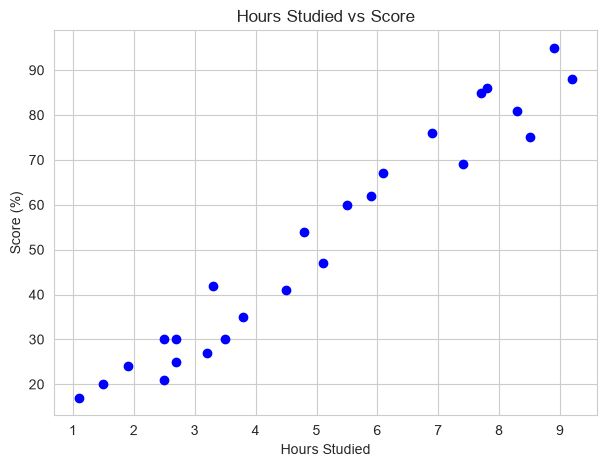

In [61]:
plt.figure(figsize=(7, 5))
plt.scatter(student_df["Hours"], student_df["Scores"], color="blue")
plt.title("Hours Studied vs Score")
plt.xlabel("Hours Studied")
plt.ylabel("Score (%)")
plt.show()

Observation: The points rise steadily from left to right, and the correlation value is very close to 1. This shows a strong positive linear relationship: more study hours lead to higher scores. This makes the data suitable for linear regression.

Train/Test Split

In [62]:
X = student_df[["Hours"]]
y = student_df["Scores"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (20, 1)
X_test : (5, 1)
y_train: (20,)
y_test : (5,)


Training the Model

In [63]:
simple_model = LinearRegression()
simple_model.fit(X_train, y_train)

print("Model trained successfully")

Model trained successfully


In [64]:
print("Intercept  :", simple_model.intercept_)
print("Coefficient:", simple_model.coef_[0])
print()
print(f"Equation: Score = {simple_model.intercept_:.2f} + {simple_model.coef_[0]:.2f} * Hours")

Intercept  : 2.0181600414346974
Coefficient: 9.910656480642233

Equation: Score = 2.02 + 9.91 * Hours


Prediction

In [65]:
y_pred = simple_model.predict(X_test)

comparison = pd.DataFrame({
    "Hours": X_test["Hours"].values,
    "Actual": y_test.values,
    "Predicted": y_pred.round(2),
})
comparison["Error"] = (comparison["Actual"] - comparison["Predicted"]).round(2)
comparison

,Hours,Actual,Predicted,Error
0,1.5,20,16.88,3.12
1,3.2,27,33.73,-6.73
2,7.4,69,75.36,-6.36
3,2.5,30,26.79,3.21
4,5.9,62,60.49,1.51


Visualise the Regression Line

The red line is the line of best fit found by the model.

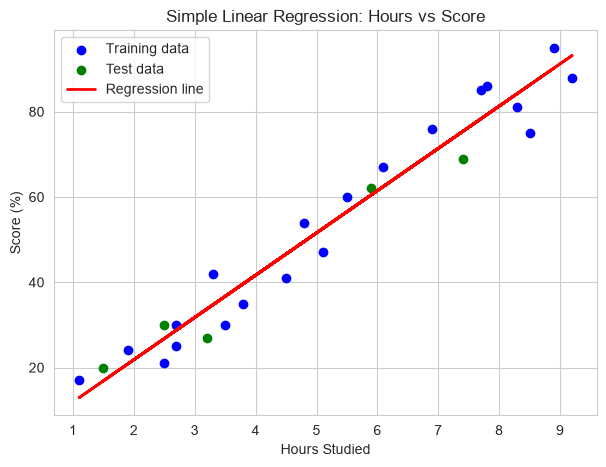

In [66]:
plt.figure(figsize=(7, 5))
plt.scatter(X_train, y_train, color="blue", label="Training data")
plt.scatter(X_test, y_test, color="green", label="Test data")
plt.plot(X, simple_model.predict(X), color="red", linewidth=2, label="Regression line")
plt.title("Simple Linear Regression: Hours vs Score")
plt.xlabel("Hours Studied")
plt.ylabel("Score (%)")
plt.legend()
plt.show()

Evaluate the Model

In [67]:
mae_a = mean_absolute_error(y_test, y_pred)
mse_a = mean_squared_error(y_test, y_pred)
rmse_a = np.sqrt(mse_a)
r2_a = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE)       : {mae_a:.4f}")
print(f"Mean Squared Error (MSE)        : {mse_a:.4f}")
print(f"Root Mean Squared Error (RMSE)  : {rmse_a:.4f}")
print(f"R2 Score                        : {r2_a:.4f}")
print()
print(f"Training R2: {simple_model.score(X_train, y_train):.4f}")
print(f"Testing R2 : {simple_model.score(X_test, y_test):.4f}")

Mean Absolute Error (MAE)       : 4.1839
Mean Squared Error (MSE)        : 21.5988
Root Mean Squared Error (RMSE)  : 4.6474
R2 Score                        : 0.9455

Training R2: 0.9516
Testing R2 : 0.9455


Interpretation: The R2 score is close to 1, which means the model explains most of the variation in student scores using only the hours studied. The MAE shows the average prediction error in score points. The training and testing R2 values are close to each other, so the model is not overfitting.

In [68]:
new_hours = pd.DataFrame({"Hours": [9.25]})
predicted_score = simple_model.predict(new_hours)

print(f"Hours studied   : 9.25")
print(f"Predicted score : {predicted_score[0]:.2f}")

Hours studied   : 9.25
Predicted score : 93.69


Part B: Multiple Linear Regression

Problem: Predict the median house value in California districts using several features.

Dataset: California Housing dataset from scikit-learn (20,640 districts, 8 features).

In [70]:
from sklearn.datasets import fetch_california_housing
housing = fetch_california_housing(as_frame=True)
housing_df = housing.frame

print("Shape (rows, columns):", housing_df.shape)
housing_df.head()

Shape (rows, columns): (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Exploratory Data Analysis (EDA)

In [71]:
housing_df.info()
housing_df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [72]:
print("Missing values per column:")
print(housing_df.isnull().sum())

Missing values per column:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


Distribution of the Target Variable

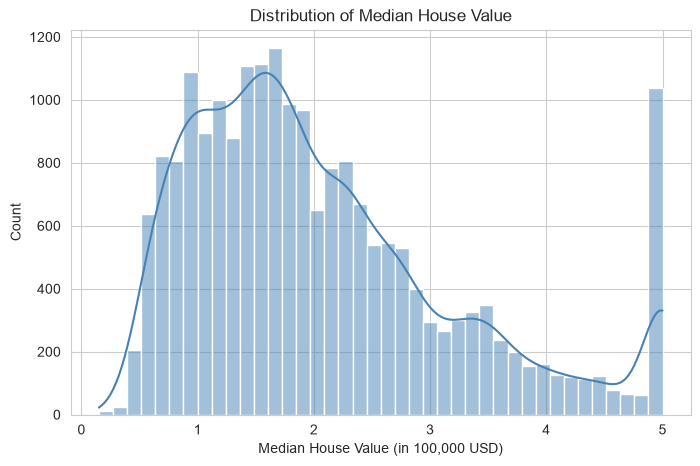

In [73]:
plt.figure(figsize=(8, 5))
sns.histplot(housing_df["MedHouseVal"], bins=40, kde=True, color="steelblue")
plt.title("Distribution of Median House Value")
plt.xlabel("Median House Value (in 100,000 USD)")
plt.show()

Correlation Between Features and Target

The correlation heatmap shows which features are most related to the house value.

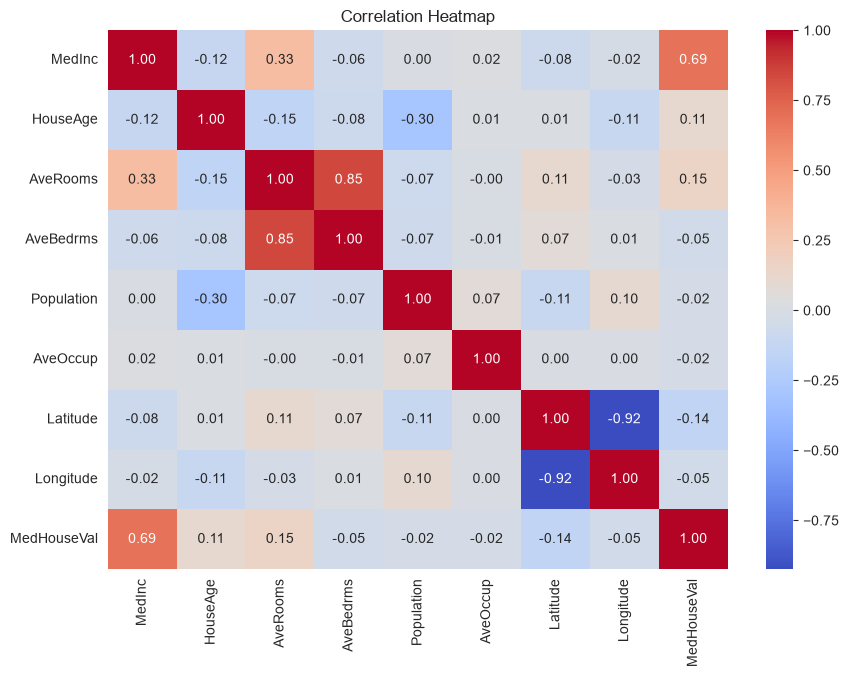

In [74]:
plt.figure(figsize=(10, 7))
sns.heatmap(housing_df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [75]:
print("Correlation of each feature with house value:")
print(housing_df.corr()["MedHouseVal"].sort_values(ascending=False))

Correlation of each feature with house value:
MedHouseVal    1.000000
MedInc         0.688075
AveRooms       0.151948
HouseAge       0.105623
AveOccup      -0.023737
Population    -0.024650
Longitude     -0.045967
AveBedrms     -0.046701
Latitude      -0.144160
Name: MedHouseVal, dtype: float64


Observation: Median income (MedInc) has the strongest positive correlation with house value, so richer areas tend to have more expensive houses. The other features have a weaker relationship with the target.

Simple Regression on One Feature (MedInc)

Before using all the features, we first check how well the single strongest feature predicts the house value.

In [76]:
X_one = housing_df[["MedInc"]]
y_all = housing_df["MedHouseVal"]

X1_train, X1_test, y1_train, y1_test = train_test_split(
    X_one, y_all, test_size=0.2, random_state=42
)

model_one = LinearRegression()
model_one.fit(X1_train, y1_train)
pred_one = model_one.predict(X1_test)

print("Intercept  :", model_one.intercept_)
print("Coefficient:", model_one.coef_[0])
print(f"R2 Score (MedInc only): {r2_score(y1_test, pred_one):.4f}")
print(f"RMSE (MedInc only)    : {np.sqrt(mean_squared_error(y1_test, pred_one)):.4f}")

Intercept  : 0.44459729169078677
Coefficient: 0.4193384939381274
R2 Score (MedInc only): 0.4589
RMSE (MedInc only)    : 0.8421


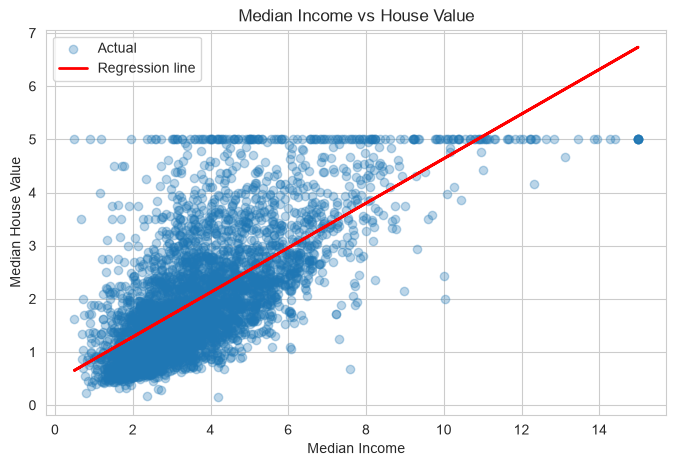

In [77]:
plt.figure(figsize=(8, 5))
plt.scatter(X1_test, y1_test, alpha=0.3, label="Actual")
plt.plot(X1_test, pred_one, color="red", linewidth=2, label="Regression line")
plt.title("Median Income vs House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.legend()
plt.show()

Multiple Linear Regression with All Features

Now all 8 features are used together. The data is split 80 percent for training and 20 percent for testing.

In [78]:
X_multi = housing_df.drop("MedHouseVal", axis=1)
y_multi = housing_df["MedHouseVal"]

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y_multi, test_size=0.2, random_state=42
)

print("X_train:", X_train_m.shape)
print("X_test :", X_test_m.shape)

X_train: (16512, 8)
X_test : (4128, 8)


In [79]:
multi_model = LinearRegression()
multi_model.fit(X_train_m, y_train_m)

print("Model trained successfully")
print("Intercept:", multi_model.intercept_)

Model trained successfully
Intercept: -37.02327770606416


Model Coefficients

Each coefficient shows how much the predicted house value changes when that feature increases by one unit, while all other features stay the same. A positive coefficient raises the price and a negative coefficient lowers it.

      Feature  Coefficient
3   AveBedrms     0.783145
0      MedInc     0.448675
1    HouseAge     0.009724
4  Population    -0.000002
5    AveOccup    -0.003526
2    AveRooms    -0.123323
6    Latitude    -0.419792
7   Longitude    -0.433708


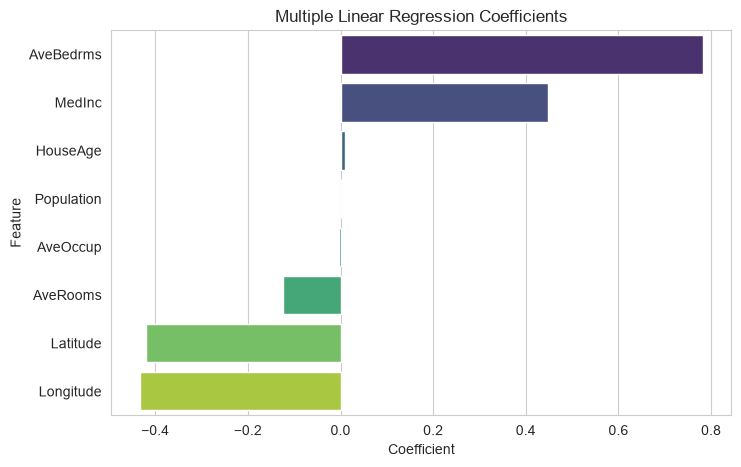

In [80]:
coef_df = pd.DataFrame({
    "Feature": X_multi.columns,
    "Coefficient": multi_model.coef_
}).sort_values(by="Coefficient", ascending=False)

print(coef_df)

plt.figure(figsize=(8, 5))
sns.barplot(x="Coefficient", y="Feature", data=coef_df, palette="viridis")
plt.title("Multiple Linear Regression Coefficients")
plt.show()

Predictions and Evaluation

In [81]:
y_pred_m = multi_model.predict(X_test_m)

comparison_m = pd.DataFrame({
    "Actual": y_test_m.values,
    "Predicted": y_pred_m.round(3),
})
comparison_m["Error"] = (comparison_m["Actual"] - comparison_m["Predicted"]).round(3)
comparison_m.head(10)

,Actual,Predicted,Error
0,0.47700,0.719,-0.242
1,0.45800,1.764,-1.306
2,5.00001,2.710,2.290
3,2.18600,2.839,-0.653
4,2.78000,2.605,0.175
5,1.58700,2.012,-0.425
6,1.98200,2.646,-0.664
7,1.57500,2.169,-0.594
8,3.40000,2.741,0.659
9,4.46600,3.916,0.550


In [82]:
mae_b = mean_absolute_error(y_test_m, y_pred_m)
mse_b = mean_squared_error(y_test_m, y_pred_m)
rmse_b = np.sqrt(mse_b)
r2_b = r2_score(y_test_m, y_pred_m)

print(f"Mean Absolute Error (MAE)       : {mae_b:.4f}")
print(f"Mean Squared Error (MSE)        : {mse_b:.4f}")
print(f"Root Mean Squared Error (RMSE)  : {rmse_b:.4f}")
print(f"R2 Score                        : {r2_b:.4f}")
print()
print(f"Training R2: {multi_model.score(X_train_m, y_train_m):.4f}")
print(f"Testing R2 : {multi_model.score(X_test_m, y_test_m):.4f}")

Mean Absolute Error (MAE)       : 0.5332
Mean Squared Error (MSE)        : 0.5559
Root Mean Squared Error (RMSE)  : 0.7456
R2 Score                        : 0.5758

Training R2: 0.6126
Testing R2 : 0.5758


Actual vs Predicted Values

If the model were perfect, all points would lie on the red diagonal line.

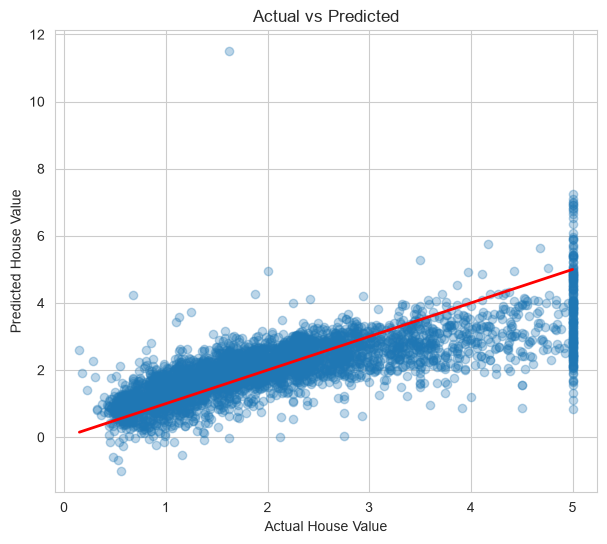

In [83]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test_m, y_pred_m, alpha=0.3)
plt.plot([y_test_m.min(), y_test_m.max()],
         [y_test_m.min(), y_test_m.max()],
         color="red", linewidth=2)
plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Actual vs Predicted")
plt.show()

Residual Analysis

Residuals are the differences between the actual and predicted values. For a good linear model, the residuals should be centred around zero and spread evenly, with no clear pattern.

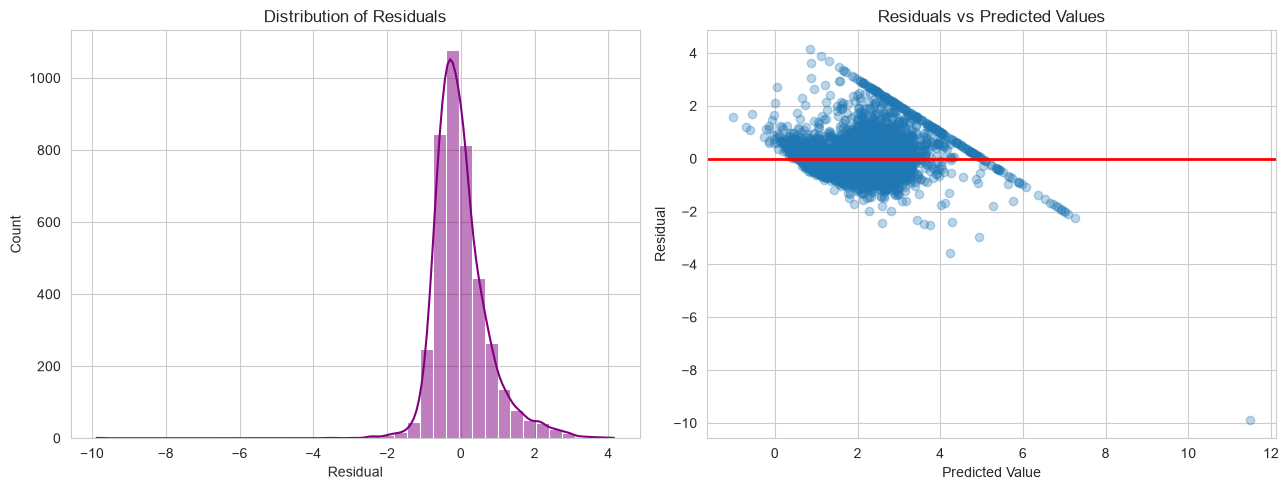

In [84]:
residuals = y_test_m - y_pred_m

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(residuals, bins=40, kde=True, ax=axes[0], color="purple")
axes[0].set_title("Distribution of Residuals")
axes[0].set_xlabel("Residual")

axes[1].scatter(y_pred_m, residuals, alpha=0.3)
axes[1].axhline(0, color="red", linewidth=2)
axes[1].set_title("Residuals vs Predicted Values")
axes[1].set_xlabel("Predicted Value")
axes[1].set_ylabel("Residual")

plt.tight_layout()
plt.show()

Interpretation: The residuals are centred close to zero, which is what we expect from a linear model. The residual plot shows some spread at higher values, which means the relationship is not perfectly linear and a more flexible model could improve the predictions.

Comparison: One Feature vs All Features

In [85]:
comparison_table = pd.DataFrame({
    "Model": ["Simple (MedInc only)", "Multiple (all 8 features)"],
    "R2 Score": [round(r2_score(y1_test, pred_one), 4), round(r2_b, 4)],
    "RMSE": [round(np.sqrt(mean_squared_error(y1_test, pred_one)), 4), round(rmse_b, 4)],
})
comparison_table

,Model,R2 Score,RMSE
0,Simple (MedInc only),0.4589,0.8421
1,Multiple (all 8 features),0.5758,0.7456


In [86]:
summary = pd.DataFrame({
    "Problem": ["Student Scores (Simple)", "California Housing (Multiple)"],
    "Features": [1, 8],
    "R2 Score": [round(r2_a, 4), round(r2_b, 4)],
    "RMSE": [round(rmse_a, 4), round(rmse_b, 4)],
})
summary

,Problem,Features,R2 Score,RMSE
0,Student Scores (Simple),1,0.9455,4.6474
1,California Housing (Multiple),8,0.5758,0.7456


Conclusion

Simple Linear Regression (student scores): The model predicted a student's score from the hours studied and reached an R2 score of 0.9455. The relationship between study hours and score is strongly linear, so the model fits the data very well.

Multiple Linear Regression (California housing): Using all 8 features, the model reached an R2 score of 0.5758. Median income was the most important feature. Using all features performed better than using median income alone.

Metrics used: MAE, MSE, RMSE and R2 score. R2 shows how much of the variation the model explains, while MAE and RMSE show the size of the prediction errors in the units of the target.

Limitations: Linear Regression assumes a straight-line relationship between features and target, and it is sensitive to outliers. The California housing data has a cap on house values and non-linear patterns, which limits the accuracy of a linear model.

Key learning: Linear Regression is a simple, fast and easy-to-interpret baseline model for predicting continuous values.

Assignment52
Week5,Day3 

Topic:MachineLearning Perform Logistic Regression. 

Reference:https://towardsdatascience.com/logistic-regression-using-python-sklearn-numpy-mnist-handwriting-recognition-matplotlibAI/ML/DeepLearning—NAVTTCAssignmentSheet-a6b31e2b166a https://www.datacamp.com/community/tutorials/understanding-logistic-regression-pythonA

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import load_digits
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report, roc_curve, roc_auc_score)

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
print("All libraries imported successfully")

All libraries imported successfully


The Sigmoid Function (Visualisation)

The plot below shows how the sigmoid function converts any input value into a probability between 0 and 1. 
The red dashed line is the 0.5 decision threshold.

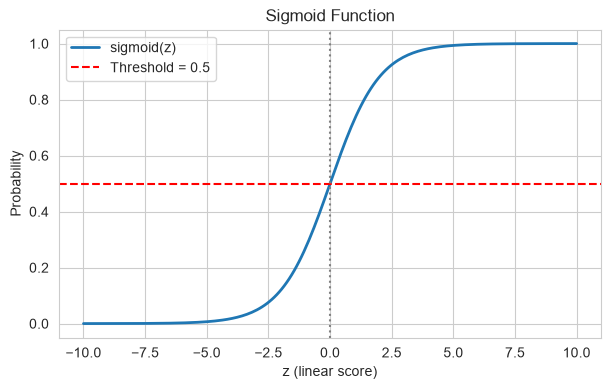

In [19]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-10, 10, 200)

plt.figure(figsize=(7, 4))
plt.plot(z, sigmoid(z), linewidth=2, label="sigmoid(z)")
plt.axhline(0.5, color="red", linestyle="--", label="Threshold = 0.5")
plt.axvline(0, color="gray", linestyle=":")
plt.xlabel("z (linear score)")
plt.ylabel("Probability")
plt.title("Sigmoid Function")
plt.legend()
plt.show()

PART A: Binary Logistic Regression (Diabetes)

Problem:Predict whether a patient has diabetes (1) or not (0) using diagnostic measurements.

Dataset: Pima Indians Diabetes Dataset (768 patients, 8 features)

Load Dataset

In [40]:
col_names = [ "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"
]

try:
    df = pd.read_csv("Dataset/pima-indians-diabetes.csv", header=None, names=col_names)
    print("Loaded local diabetes.csv")
except FileNotFoundError:
    url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
    df = pd.read_csv(url, header=None, names=col_names)
    print("Loaded dataset from online source")

print(df["Outcome"].value_counts())

Loaded local diabetes.csv
Outcome
0    500
1    268
Name: count, dtype: int64


Exploratory Data Analysis (EDA)

Look at the shape, data types, summary statistics, missing values and class balance of the data.

In [21]:
print("Shape (rows, columns):", df.shape)
print("\n--- Info ---")
df.info()

Shape (rows, columns): (767, 9)

--- Info ---
<class 'pandas.DataFrame'>
RangeIndex: 767 entries, 0 to 766
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   6       767 non-null    int64  
 1   148     767 non-null    int64  
 2   72      767 non-null    int64  
 3   35      767 non-null    int64  
 4   0       767 non-null    int64  
 5   33.6    767 non-null    float64
 6   0.627   767 non-null    float64
 7   50      767 non-null    int64  
 8   1       767 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [22]:
df.describe()

,6,148,72,35,0,33.6,0.627,50,1
count,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000
mean,3.842243,120.859192,69.101695,20.517601,79.903520,31.990482,0.471674,33.219035,0.348110
std,3.370877,31.978468,19.368155,15.954059,115.283105,7.889091,0.331497,11.752296,0.476682
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243500,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,32.000000,32.000000,0.371000,29.000000,0.000000
75%,6.000000,140.000000,80.000000,32.000000,127.500000,36.600000,0.625000,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [28]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nClass distribution:")
print(df['Outcome'].value_counts())
print("\nClass percentage:")
print(df['Outcome'].value_counts(normalize=True) * 100)

Missing values per column:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Class distribution:
Outcome
0    500
1    268
Name: count, dtype: int64

Class percentage:
Outcome
0    65.104167
1    34.895833
Name: proportion, dtype: float64


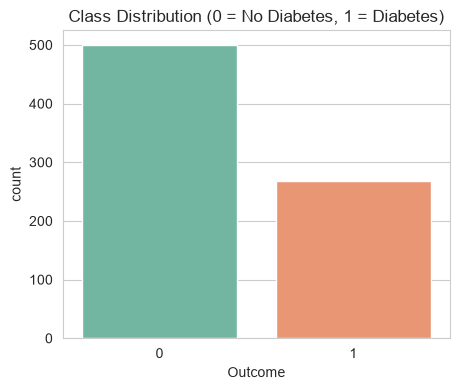

In [29]:
plt.figure(figsize=(5, 4))
sns.countplot(x='Outcome', data=df, palette="Set2")
plt.title("Class Distribution (0 = No Diabetes, 1 = Diabetes)")
plt.show()

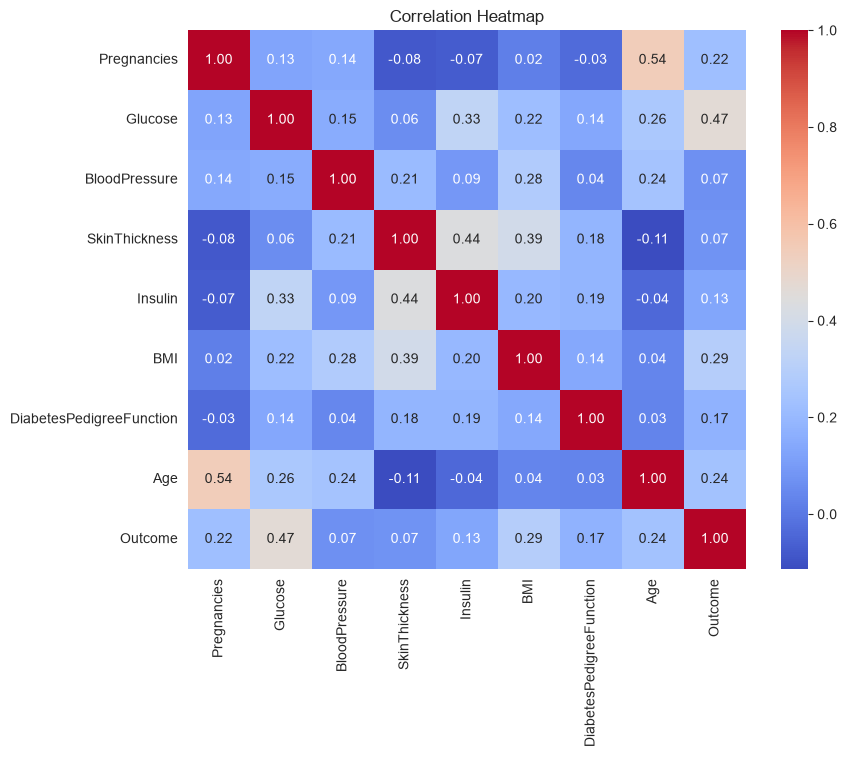

In [30]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

Observations (EDA)
The dataset has 768 rows and 9 columns (8 features + 1 target).
There are no NaN values, but several columns (Glucose, BloodPressure, SkinThickness, Insulin, BMI) contain 0 values, which are biologically impossible and really represent missing data.
The classes are imbalanced: roughly 65% non-diabetic and 35% diabetic.
Glucose has the strongest correlation with the Outcome, followed by BMI and Age.

Data Cleaning

A glucose or BMI of 0 is not possible, so these zeros are treated as missing values. We replace them with the median of each column.

In [31]:
cols_with_zero = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

print("Zero counts BEFORE cleaning:")
print((df[cols_with_zero] == 0).sum())

for c in cols_with_zero:
    df[c] = df[c].replace(0, np.nan)
    df[c] = df[c].fillna(df[c].median())

print("\nZero counts AFTER cleaning:")
print((df[cols_with_zero] == 0).sum())

Zero counts BEFORE cleaning:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Zero counts AFTER cleaning:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


Spliting into Features and Target, then Train/Test Split

In [32]:
X = df.drop('Outcome', axis=1)
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (576, 8)
X_test : (192, 8)
y_train: (576,)
y_test : (192,)


Feature Scaling

Features have very different ranges (e.g. Insulin is in the hundreds, DiabetesPedigreeFunction is below 3). StandardScaler brings every feature to mean 0 and standard deviation 1, which helps logistic regression converge faster and makes the coefficients comparable.

The scaler is fitted on the training data only and then applied to the test data to avoid data leakage.

In [33]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling done")
print("Train mean (approx):", X_train_scaled.mean().round(3))
print("Train std  (approx):", X_train_scaled.std().round(3))

Scaling done
Train mean (approx): -0.0
Train std  (approx): 1.0


Building and Training the Logistic Regression Model

In [34]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

print("Model trained successfully")
print("Intercept:", model.intercept_)

Model trained successfully
Intercept: [-0.86412588]


Model Coefficients (Feature Importance)

Each coefficient shows how a feature affects the log odds of having diabetes. 
A positive coefficient increases the chance of diabetes and a negative one decreases it. Because the data is scaled, the sizes of the coefficients can be compared directly.

                    Feature  Coefficient
1                   Glucose     1.161295
5                       BMI     0.723999
0               Pregnancies     0.440493
6  DiabetesPedigreeFunction     0.212284
7                       Age     0.126013
4                   Insulin    -0.030734
2             BloodPressure    -0.057326
3             SkinThickness    -0.058342


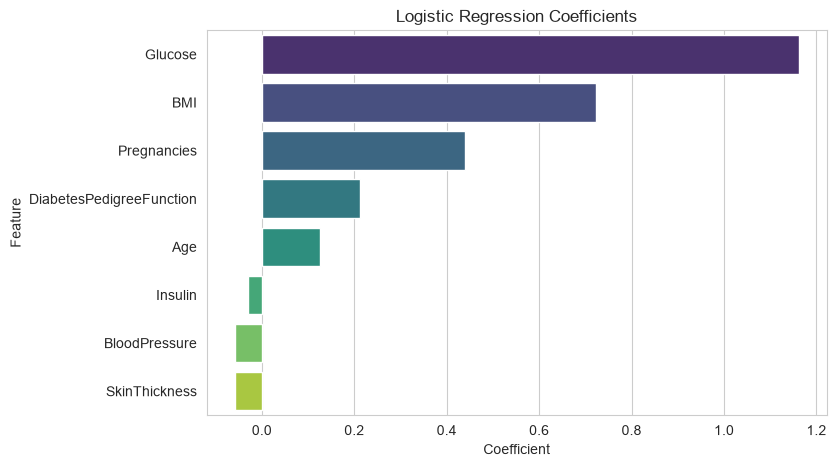

In [35]:
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

print(coef_df)

plt.figure(figsize=(8, 5))
sns.barplot(x='Coefficient', y='Feature', data=coef_df, palette="viridis")
plt.title("Logistic Regression Coefficients")
plt.show()

Predictions and Evaluation

In [36]:
y_pred = model.predict(X_test_scaled)

train_acc = accuracy_score(y_train, model.predict(X_train_scaled))
test_acc = accuracy_score(y_test, y_pred)
acc_diabetes = test_acc   # saved for the conclusion

print(f"Training Accuracy: {train_acc:.4f}")
print(f"Testing Accuracy : {test_acc:.4f}")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=["No Diabetes", "Diabetes"]))

Training Accuracy: 0.7899
Testing Accuracy : 0.7292

Classification Report:

              precision    recall  f1-score   support

 No Diabetes       0.77      0.84      0.80       125
    Diabetes       0.64      0.52      0.57        67

    accuracy                           0.73       192
   macro avg       0.70      0.68      0.69       192
weighted avg       0.72      0.73      0.72       192



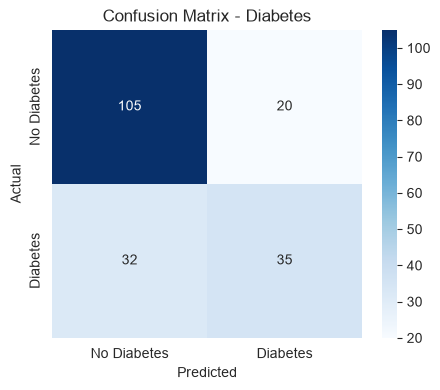

True Negatives (TN) : 105
False Positives (FP): 20
False Negatives (FN): 32
True Positives (TP) : 35


In [37]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["No Diabetes", "Diabetes"],
            yticklabels=["No Diabetes", "Diabetes"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Diabetes")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Negatives (TN) : {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives (TP) : {tp}")

The Metrics

TP (True Positive): the patient has diabetes and the model predicted diabetes.

TN (True Negative): the patient is healthy and the model predicted healthy.

FP (False Positive): the patient is healthy but the model predicted diabetes (false alarm).

FN (False Negative): the patient has diabetes but the model predicted healthy (missed case).

Accuracy = (TP + TN) / total predictions.
Precision = TP / (TP + FP): of all predicted diabetics, how many really are diabetic.
Recall = TP / (TP + FN): of all real diabetics, how many the model caught.

F1-score: the harmonic mean of precision and recall.

In medical problems, recall for the positive class is very important, because a missed diabetic patient (FN) is more dangerous than a false alarm.

ROC Curve and AUC

The ROC curve plots the True Positive Rate against the False Positive Rate at every possible threshold. The Area Under the Curve summarises it in one number: 1.0 is perfect and 0.5 is random guessing.

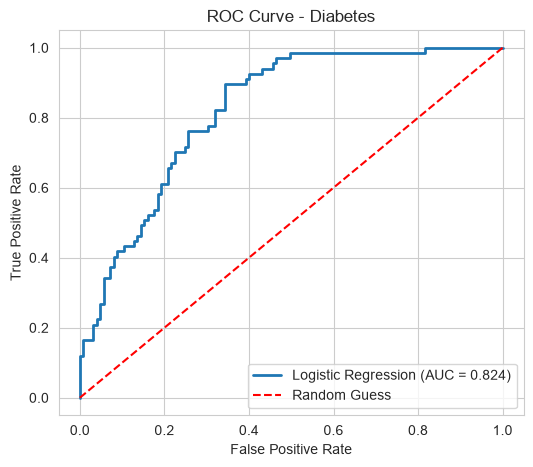

AUC Score: 0.8239


In [38]:
y_prob = model.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, linewidth=2, label=f"Logistic Regression (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], 'r--', label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Diabetes")
plt.legend()
plt.show()

print(f"AUC Score: {auc:.4f}")

Predicting for a New Patient

We can give the trained model a new patient's data and get both the predicted class and the probability.

In [39]:
# Order: Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, DiabetesPedigreeFunction, Age
new_patient = pd.DataFrame([[2, 148, 72, 35, 125, 33.6, 0.627, 50]], columns=X.columns)

new_scaled = scaler.transform(new_patient)
pred = model.predict(new_scaled)[0]
prob = model.predict_proba(new_scaled)[0]

print("Prediction:", "Diabetic" if pred == 1 else "Not Diabetic")
print(f"Probability of No Diabetes: {prob[0]:.3f}")
print(f"Probability of Diabetes   : {prob[1]:.3f}")

Prediction: Diabetic
Probability of No Diabetes: 0.436
Probability of Diabetes   : 0.564


PART B: Multiclass Logistic Regression (Digits)

Problem: Recognise handwritten digits (0 to 9) from images.

Dataset: scikit-learn Digits dataset a smaller MNIST-style dataset with 1,797 images, each 8x8 pixels (64 features). Each pixel holds an intensity value from 0 (white) to 16 (black).

Here there are 10 classes so logistic regression works in multinomial (multiclass) mode: it gives a probability for each digit and predicts the digit with the highest probability.

Loading the Dataset

In [42]:
import pandas as pd
from sklearn.datasets import load_digits

# 1. Load the dataset from scikit-learn
digits = load_digits()

# 2. Create column names for the 64 pixels (pixel_0, pixel_1, ..., pixel_63)
column_names = [f"pixel_{i}" for i in range(64)]

# 3. Create a DataFrame for the features
df = pd.DataFrame(digits.data, columns=column_names)

# 4. Add the target/label column
df['target'] = digits.target

# 5. Export to a CSV file
df.to_csv("digits_dataset.csv", index=False)
print("Dataset successfully saved to 'digits_dataset.csv'!")


Dataset successfully saved to 'digits_dataset.csv'!


In [43]:
digits = load_digits()

print("Image data shape :", digits.images.shape)
print("Feature matrix   :", digits.data.shape)
print("Target shape     :", digits.target.shape)
print("Classes          :", np.unique(digits.target))

Image data shape : (1797, 8, 8)
Feature matrix   : (1797, 64)
Target shape     : (1797,)
Classes          : [0 1 2 3 4 5 6 7 8 9]


Visualise Sample Images

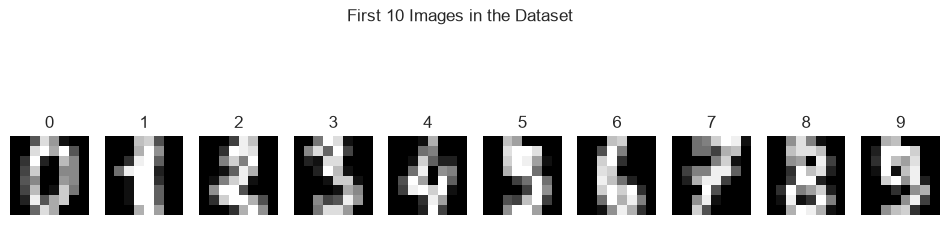

In [44]:
plt.figure(figsize=(12, 3))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(digits.images[i], cmap='gray')
    plt.title(f"{digits.target[i]}")
    plt.axis('off')
plt.suptitle("First 10 Images in the Dataset", y=1.05)
plt.show()

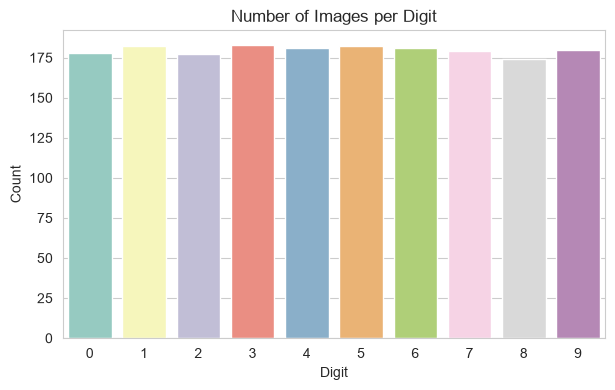

In [45]:
# How many images per digit?
plt.figure(figsize=(7, 4))
sns.countplot(x=digits.target, palette="Set3")
plt.xlabel("Digit")
plt.ylabel("Count")
plt.title("Number of Images per Digit")
plt.show()

Train/Test Split

Each 8x8 image is already flattened into 64 features. 
The data is split 75% / 25%.

In [46]:
X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(
    digits.data, digits.target, test_size=0.25, random_state=42, stratify=digits.target
)

print("Training set:", X_train_d.shape)
print("Testing set :", X_test_d.shape)

Training set: (1347, 64)
Testing set : (450, 64)


Train the Model

In [47]:
clf = LogisticRegression(max_iter=5000, random_state=42)
clf.fit(X_train_d, y_train_d)

print("Model trained successfully")
print("Coefficient matrix shape:", clf.coef_.shape, "(10 classes x 64 pixels)")

Model trained successfully
Coefficient matrix shape: (10, 64) (10 classes x 64 pixels)


Evaluate the Model

In [48]:
pred_d = clf.predict(X_test_d)

train_acc_d = clf.score(X_train_d, y_train_d)
test_acc_d = clf.score(X_test_d, y_test_d)
acc_digits = test_acc_d   # saved for the conclusion

print(f"Training Accuracy: {train_acc_d:.4f}")
print(f"Testing Accuracy : {test_acc_d:.4f}")
print("\nClassification Report:\n")
print(classification_report(y_test_d, pred_d))

Training Accuracy: 1.0000
Testing Accuracy : 0.9622

Classification Report:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        45
           1       0.90      0.93      0.91        46
           2       1.00      0.98      0.99        44
           3       0.98      1.00      0.99        46
           4       0.96      1.00      0.98        45
           5       0.98      0.98      0.98        46
           6       0.98      0.98      0.98        45
           7       1.00      0.98      0.99        45
           8       0.86      0.86      0.86        43
           9       0.98      0.91      0.94        45

    accuracy                           0.96       450
   macro avg       0.96      0.96      0.96       450
weighted avg       0.96      0.96      0.96       450



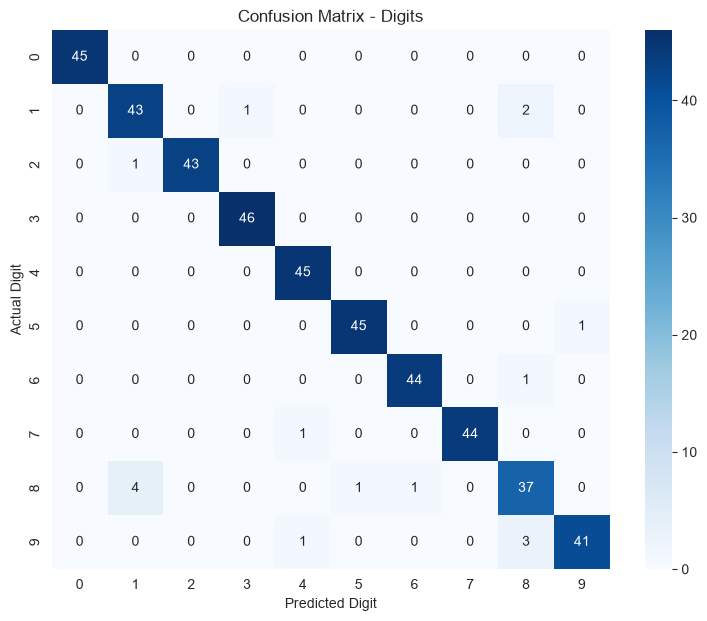

In [49]:
cm_d = confusion_matrix(y_test_d, pred_d)

plt.figure(figsize=(9, 7))
sns.heatmap(cm_d, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("Confusion Matrix - Digits")
plt.show()

Analyse Correct and Incorrect Predictions

Looking at the images the model got wrong helps us understand its weaknesses.

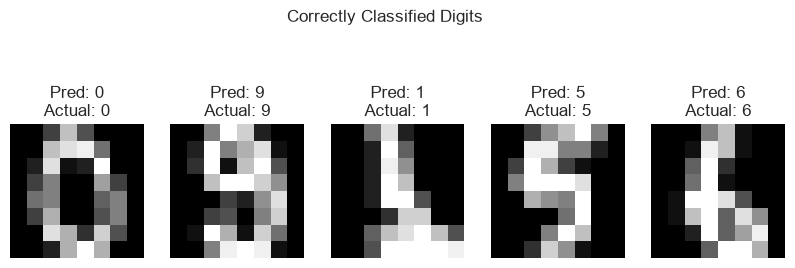

In [50]:
# Correct predictions
correct_idx = np.where(pred_d == y_test_d)[0][:5]

plt.figure(figsize=(10, 3))
for i, idx in enumerate(correct_idx):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_test_d[idx].reshape(8, 8), cmap='gray')
    plt.title(f"Pred: {pred_d[idx]}\nActual: {y_test_d[idx]}")
    plt.axis('off')
plt.suptitle("Correctly Classified Digits", y=1.1)
plt.show()

Total misclassified images: 17 out of 450


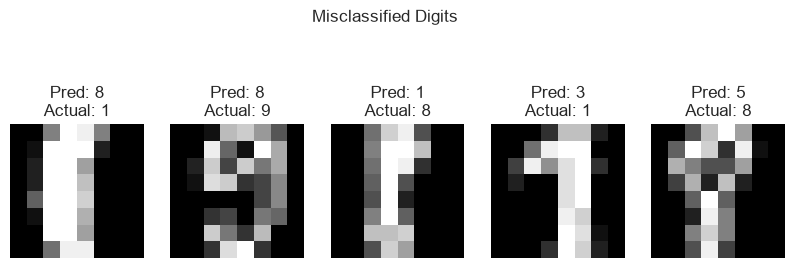

In [51]:
# Wrong predictions
wrong_idx = np.where(pred_d != y_test_d)[0]
print(f"Total misclassified images: {len(wrong_idx)} out of {len(y_test_d)}")

n_show = min(5, len(wrong_idx))
plt.figure(figsize=(10, 3))
for i, idx in enumerate(wrong_idx[:n_show]):
    plt.subplot(1, n_show, i + 1)
    plt.imshow(X_test_d[idx].reshape(8, 8), cmap='gray')
    plt.title(f"Pred: {pred_d[idx]}\nActual: {y_test_d[idx]}")
    plt.axis('off')
plt.suptitle("Misclassified Digits", y=1.1)
plt.show()

Predicting a Single Digit with Probabilities

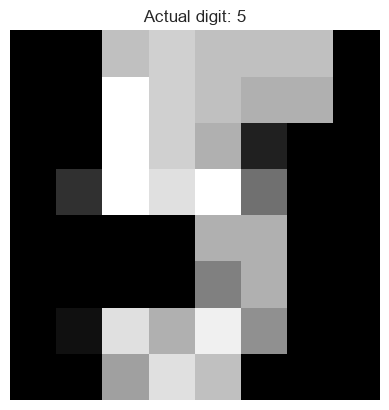

Predicted digit: 5

Probability for each digit:
  0: 0.0000
  1: 0.0000
  2: 0.0000
  3: 0.0000
  4: 0.0000
  5: 0.9999
  6: 0.0000
  7: 0.0000
  8: 0.0000
  9: 0.0001


In [52]:
sample_no = 10
sample = X_test_d[sample_no].reshape(1, -1)

plt.imshow(X_test_d[sample_no].reshape(8, 8), cmap='gray')
plt.title(f"Actual digit: {y_test_d[sample_no]}")
plt.axis('off')
plt.show()

probs = clf.predict_proba(sample)[0]
print("Predicted digit:", clf.predict(sample)[0])
print("\nProbability for each digit:")
for digit, p in enumerate(probs):
    print(f"  {digit}: {p:.4f}")

In [53]:
summary = pd.DataFrame({
    "Problem": ["Diabetes (Binary)", "Digits (Multiclass)"],
    "Classes": [2, 10],
    "Test Accuracy": [round(acc_diabetes, 4), round(acc_digits, 4)]
})
summary

,Problem,Classes,Test Accuracy
0,Diabetes (Binary),2,0.7292
1,Digits (Multiclass),10,0.9622


Conclusion

In this assignment, Logistic Regression was implemented on two classification problems using scikit-learn.

1. Diabetes prediction (binary): After replacing impossible zero values with medians and scaling the features, the model reached a test accuracy of 0.7292. Glucose was the most influential feature. The accuracy is moderate because the classes are imbalanced and logistic regression can only draw a linear decision boundary.

2. Digit recognition (multiclass): The model reached a test accuracy of 0.9622. Most errors were caused by messy handwriting and the low 8x8 resolution.

Metrics used: accuracy, precision, recall, F1-score, confusion matrix and ROC-AUC. Accuracy alone can be misleading on imbalanced data, so the other metrics were used as well.

Limitations: Logistic regression assumes a linear relationship between the features and the log-odds, so it cannot capture complex patterns.

Key learning: Logistic Regression is a simple, fast and interpretable baseline model for classification problems.